# Main Topic - Driveability

### Link - Sriram
https://data.wprdc.org/dataset/allegheny-county-crash-data

https://data.wprdc.org/dataset/neighborhoods2

In [1]:
import pandas as pd
import geopandas as gpd



True
7019
(90, 41)
0


<Axes: >

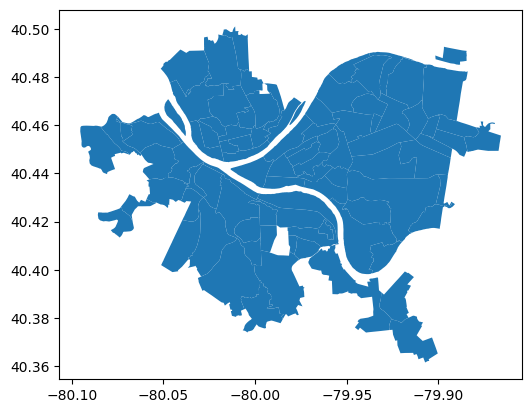

In [10]:
import json
import pandas as pd
import geopandas as gpd
from shapely import wkb

# Load the datastore export
with open("geodata.json", "r", encoding="utf-8") as f:
    data = json.load(f)

columns = [fld["id"] for fld in data["fields"]]
records = pd.DataFrame(data["records"], columns=columns)

# Strip the leading "\x" and decode the hex WKB into shapely geometries
def parse_wkb(s):
    if s is None:
        return None
    if s.startswith("\\x"):
        s = s[2:]
    return wkb.loads(s, hex=True)

records["geometry"] = records["dataspatial_wkb"].apply(parse_wkb)

neighborhoods = gpd.GeoDataFrame(
    records.drop(columns=["dataspatial_wkb"]),
    geometry="geometry",
    crs="EPSG:4326",   # the coordinates (~ -79.9, 40.4) are already lat/lon
)

# Crashes
crash = pd.read_csv("crash_allegheny_2025.csv")
crash = crash.dropna(subset=["DEC_LONGITUDE", "DEC_LATITUDE"])

crashes_gdf = gpd.GeoDataFrame(
    crash,
    geometry=gpd.points_from_xy(crash["DEC_LONGITUDE"], crash["DEC_LATITUDE"]),
    crs="EPSG:4326",
)

# Spatial join
joined = gpd.sjoin(
    crashes_gdf,
    neighborhoods[["hood", "geometry"]],
    how="left",
    predicate="within",
)

joined = joined.rename(columns={"hood": "neighborhood"}).drop(columns=["geometry", "index_right"])

print(len(joined) == len(crashes_gdf))      # should be True (no duplicate matches)
print(joined["neighborhood"].isna().sum())  # crashes outside the city polygons
joined.to_csv("crashes_with_neighborhoods.csv", index=False)

print(neighborhoods.shape)
print(neighborhoods.geometry.isna().sum())
neighborhoods.plot()